# k-NN vs Voting V8

For V8, I wanted to see if giving less common image features a bit more weight would help k-NN. I kept the distance-gap rule from V7 and tried using NN V2 and V4 when they agreed.

First, I imported the libraries and functions I'll need.

In [1]:
from pathlib import Path
from time import perf_counter
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

project_root = Path.cwd()
if not (project_root / 'src').is_dir():
    project_root = project_root.parent
sys.path.insert(0, str(project_root))
from src.data_loader import load_task, split_train_val
from src.models.knn import KNNClassifier, euclidean_distance

result_dir = project_root / 'results/model_comparison'
result_dir.mkdir(parents=True, exist_ok=True)

I loaded the same image split and checked the saved predictions against the validation labels.

In [2]:
X, y, X_test, test_ids = load_task('image')
X_train, X_val, y_train, y_val = split_train_val(X, y, val_fraction=0.2, seed=42)
assert X_train.shape == (16000, 500) and X_val.shape == (4000, 500)
assert X.shape == (20000, 500) and X_test.shape == (5000, 500)
v5_knn = pd.read_csv(result_dir / 'knn_vs_voting_v5_knn_validation.csv')
v5_vote = pd.read_csv(result_dir / 'knn_vs_voting_v5_image_validation.csv')
v6_vote = pd.read_csv(result_dir / 'knn_vs_voting_v6_image_validation.csv')
v7_vote = pd.read_csv(result_dir / 'knn_vs_voting_v7_image_validation.csv')
nn2 = pd.read_csv(project_root / 'results/image/nn_v2_validation.csv')
nn4 = pd.read_csv(project_root / 'results/image/nn_v4_validation.csv')
for frame in [v5_knn, v5_vote, v6_vote, v7_vote, nn2, nn4]:
    assert frame.columns.tolist() == ['validation_index', 'actual_label', 'predicted_label']
    assert len(frame) == 4000 and not frame.isna().any().any()
    assert np.array_equal(frame.validation_index, np.arange(4000)) and np.array_equal(frame.actual_label, y_val)
    assert pd.api.types.is_integer_dtype(frame.predicted_label) and frame.predicted_label.between(0, 49).all()

I counted how often each feature appeared in the training images. I used the weights before calculating the mean, then subtracted half that mean and normalized each image.

In [3]:
def normalize_rows(features):
    lengths = np.linalg.norm(features, axis=1, keepdims=True)
    assert np.isfinite(features).all() and (lengths > 0).all()
    return features / lengths


def nearest_class_gaps(model, features):
    assert len(np.unique(model.y_train)) > 1
    nearest_distances = []
    other_distances = []
    gaps = []
    nearest_labels = []
    for image in features:
        distances = euclidean_distance(image, model.X_train)
        nearest_index = int(np.argmin(distances))
        knn_label = model.y_train[nearest_index]
        d1 = distances[nearest_index]
        d_other = np.min(distances[model.y_train != knn_label])
        nearest_distances.append(d1)
        other_distances.append(d_other)
        gaps.append(d_other - d1)
        nearest_labels.append(knn_label)
    return (np.asarray(nearest_distances), np.asarray(other_distances),
            np.asarray(gaps), np.asarray(nearest_labels))

assert (X_train >= 0).all() and (X_val >= 0).all()
feature_counts = (X_train > 0).sum(axis=0)
frequency_weights = np.log((len(X_train) + 1) / (feature_counts + 1)) + 1
frequency_weights = frequency_weights.astype(np.float32) ** 0.4
weighted_train = np.sqrt(X_train) * frequency_weights
feature_mean = weighted_train.mean(axis=0)
assert frequency_weights.shape == feature_mean.shape == (500,)
train_centered = normalize_rows(weighted_train - 0.5 * feature_mean)
val_centered = normalize_rows(np.sqrt(X_val) * frequency_weights - 0.5 * feature_mean)
assert train_centered.dtype == val_centered.dtype == np.float32
model = KNNClassifier(k=1, distance_fn=euclidean_distance, voting_method='majority')
model.fit(train_centered, y_train)
start = perf_counter()
validation_distances, validation_other_distances, validation_gaps, knn_predictions = nearest_class_gaps(model, val_centered)
assert np.array_equal(model.predict(val_centered[:5]), knn_predictions[:5])
assert np.isfinite(validation_gaps).all() and (validation_gaps >= -1e-6).all()
cutoff = np.percentile(validation_gaps[:2000], 35)
print('Validation gap cutoff:', cutoff)
print(f'Validation neighbors calculated in {perf_counter() - start:.2f} s')

Validation gap cutoff: 0.01659826636314392
Validation neighbors calculated in 279.58 s


I used NN V2 only when NN V2 and V4 agreed and the gap was at or below the 35th-percentile cutoff from the first 2000 images.

In [4]:
def conditional_vote(knn_labels, gaps, nn2_labels, nn4_labels, cutoff):
    use_nn = (gaps <= cutoff) & (nn2_labels == nn4_labels)
    predictions = knn_labels.copy()
    predictions[use_nn] = nn2_labels[use_nn]
    return predictions, use_nn

v8_predictions, use_nn = conditional_vote(
    knn_predictions, validation_gaps, nn2.predicted_label.to_numpy(),
    nn4.predicted_label.to_numpy(), cutoff)
validation = pd.DataFrame({'validation_index': np.arange(4000),
    'actual_label': y_val, 'predicted_label': v8_predictions})
validation.to_csv(result_dir / 'knn_vs_voting_v8_image_validation.csv', index=False)
gap_details = pd.DataFrame({'validation_index': np.arange(4000),
    'actual_label': y_val, 'knn_label': knn_predictions,
    'nearest_distance': validation_distances, 'other_class_distance': validation_other_distances,
    'distance_gap': validation_gaps, 'nn2_label': nn2.predicted_label.to_numpy(),
    'nn4_label': nn4.predicted_label.to_numpy(), 'used_nn': use_nn,
    'predicted_label': v8_predictions})
gap_details.to_csv(result_dir / 'knn_vs_voting_v8_gap_validation.csv', index=False)
print('NN agreement and gap cutoff met:', int(use_nn.sum()))
print('Labels changed from weighted k-NN:', int((v8_predictions != knn_predictions).sum()))

NN agreement and gap cutoff met: 539
Labels changed from weighted k-NN: 427


I compared weighted k-NN and the new vote with the saved results. I also checked both halves of the same validation split.

In [5]:
rows = []
for name, predictions in [
    ('V5 conditional', v5_vote.predicted_label.to_numpy()),
    ('V6 conditional', v6_vote.predicted_label.to_numpy()),
    ('V7 conditional', v7_vote.predicted_label.to_numpy()),
    ('V8 weighted k-NN', knn_predictions),
    ('V8 conditional', v8_predictions)]:
    correct = int((predictions == y_val).sum())
    rows.append({'candidate': name, 'correct_count': correct,
                 'validation_samples': len(y_val), 'validation_accuracy': correct / len(y_val)})
summary = pd.DataFrame(rows)
summary.to_csv(result_dir / 'knn_vs_voting_v8_summary.csv', index=False)
print(summary.to_string(index=False))
knn_correct = int((knn_predictions == y_val).sum())
v5_knn_correct = int((v5_knn.predicted_label.to_numpy() == y_val).sum())
print('Additional correct images over V5 k-NN:', knn_correct - v5_knn_correct)
v7_labels = v7_vote.predicted_label.to_numpy()
old_correct = v7_labels == y_val
new_correct = v8_predictions == y_val
print('Labels changed from V7:', int((v8_predictions != v7_labels).sum()))
print('Previously wrong predictions corrected:', int((~old_correct & new_correct).sum()))
print('Previously correct predictions lost:', int((old_correct & ~new_correct).sum()))
print('Net additional correct images:', int(new_correct.sum() - old_correct.sum()))
for start, end in [(0, 2000), (2000, 4000)]:
    old_count = int(old_correct[start:end].sum())
    new_count = int(new_correct[start:end].sum())
    print(f'Validation positions {start}..{end-1}: V7={old_count}/2000 ({old_count/2000:.3%}), '
          f'V8={new_count}/2000 ({new_count/2000:.3%}), gain={new_count-old_count}')

       candidate  correct_count  validation_samples  validation_accuracy
  V5 conditional           2306                4000              0.57650
  V6 conditional           2350                4000              0.58750
  V7 conditional           2363                4000              0.59075
V8 weighted k-NN           2312                4000              0.57800
  V8 conditional           2387                4000              0.59675
Additional correct images over V5 k-NN: 28
Labels changed from V7: 557
Previously wrong predictions corrected: 113
Previously correct predictions lost: 89
Net additional correct images: 24
Validation positions 0..1999: V7=1185/2000 (59.250%), V8=1194/2000 (59.700%), gain=9
Validation positions 2000..3999: V7=1178/2000 (58.900%), V8=1193/2000 (59.650%), gain=15


I plotted the image accuracies to compare the new features and vote with the earlier results.

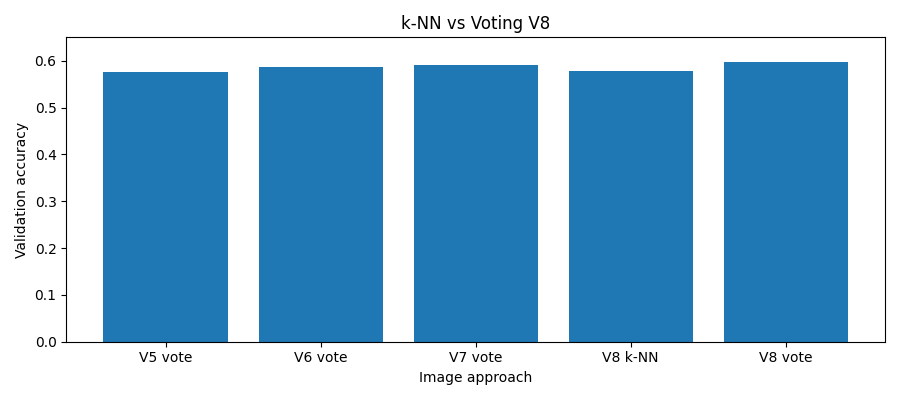

In [6]:
plt.figure(figsize=(9, 4))
plt.bar(['V5 vote', 'V6 vote', 'V7 vote', 'V8 k-NN', 'V8 vote'], summary.validation_accuracy)
plt.xlabel('Image approach')
plt.ylabel('Validation accuracy')
plt.title('k-NN vs Voting V8')
plt.ylim(0, 0.65)
plt.tight_layout()
plt.savefig(result_dir / 'knn_vs_voting_v8_accuracy.png')
plt.show()

I kept NN V3 for sentiment and calculated the combined accuracy as the equal average of both tasks.

In [7]:
sentiment = pd.read_csv(project_root / 'results/sentiment/nn_v3_validation.csv')
sentiment_X, sentiment_y, sentiment_X_test, sentiment_test_ids = load_task('sentiment')
_, _, _, sentiment_y_val = split_train_val(sentiment_X, sentiment_y, val_fraction=0.2, seed=42)
assert len(sentiment) == 2400 and not sentiment.isna().any().any()
assert np.array_equal(sentiment.validation_index, np.arange(2400)) and np.array_equal(sentiment.actual_label, sentiment_y_val)
sentiment_correct = int((sentiment.predicted_label == sentiment.actual_label).sum())
sentiment_accuracy = sentiment_correct / len(sentiment)
image_accuracy = float((v8_predictions == y_val).mean())
combined_accuracy = (image_accuracy + sentiment_accuracy) / 2
print(f'NN V3 sentiment: {sentiment_correct}/{len(sentiment)}, accuracy={sentiment_accuracy:.4%}')
print('Combined validation accuracy:', combined_accuracy)

NN V3 sentiment: 1639/2400, accuracy=68.2917%
Combined validation accuracy: 0.6398333333333333


I recalculated the feature weights and mean using all 20000 training images. I used them for the test images and set a fresh cutoff from the 5000 test gaps.

In [8]:
X, y, X_test, test_ids = load_task('image')
assert X.shape == (20000, 500) and X_test.shape == (5000, 500)
assert (X >= 0).all() and (X_test >= 0).all()
full_feature_counts = (X > 0).sum(axis=0)
full_frequency_weights = np.log((len(X) + 1) / (full_feature_counts + 1)) + 1
full_frequency_weights = full_frequency_weights.astype(np.float32) ** 0.4
weighted_all = np.sqrt(X) * full_frequency_weights
full_feature_mean = weighted_all.mean(axis=0)
all_centered = normalize_rows(weighted_all - 0.5 * full_feature_mean)
test_centered = normalize_rows(np.sqrt(X_test) * full_frequency_weights - 0.5 * full_feature_mean)
assert all_centered.dtype == test_centered.dtype == np.float32
test_model = KNNClassifier(k=1, distance_fn=euclidean_distance, voting_method='majority')
test_model.fit(all_centered, y)
start = perf_counter()
test_distances, test_other_distances, test_gaps, test_knn_labels = nearest_class_gaps(test_model, test_centered)
assert np.array_equal(test_model.predict(test_centered[:5]), test_knn_labels[:5])
assert np.isfinite(test_gaps).all() and (test_gaps >= -1e-6).all()
test_cutoff = np.percentile(test_gaps, 35)
print('Test gap cutoff:', test_cutoff)
print(f'Test neighbors calculated in {perf_counter() - start:.2f} s')

Test gap cutoff: 0.01943770051002502
Test neighbors calculated in 477.46 s


I matched NN V2 and V4 by image ID and applied the same gap rule.

In [9]:
sample = pd.read_csv(project_root / 'data/raw/sample_submission.csv')
text_ids = pd.Series(sentiment_test_ids)
assert sample.columns.tolist() == ['id', 'label'] and len(sample) == 10000 and sample.id.is_unique
assert len(test_ids) == len(text_ids) == 5000 and len(set(test_ids)) == 5000 and text_ids.is_unique
assert set(test_ids).isdisjoint(set(text_ids)) and set(sample.id) == set(test_ids) | set(text_ids)
is_image = sample.id.isin(test_ids)
is_text = sample.id.isin(text_ids)

def align_submission(path, ids):
    frame = pd.read_csv(path)
    assert frame.columns.tolist() == ['id', 'label'] and len(frame) == 10000
    assert frame.id.is_unique and set(frame.id) == set(sample.id) and not frame.isna().any().any()
    assert pd.api.types.is_integer_dtype(frame.label)
    aligned = pd.DataFrame({'id': ids}).merge(frame, on='id', how='left', sort=False, validate='one_to_one')
    assert aligned.id.tolist() == list(ids) and not aligned.isna().any().any()
    return aligned

nn2_images = align_submission(project_root / 'submission/nn/submission_v2_nn.csv', test_ids)
nn4_images = align_submission(project_root / 'submission/nn/submission_v4_nn.csv', test_ids)
test_predictions, test_use_nn = conditional_vote(test_knn_labels, test_gaps,
    nn2_images.label.to_numpy(), nn4_images.label.to_numpy(), test_cutoff)
print('Image labels changed from weighted k-NN:', int((test_predictions != test_knn_labels).sum()))

Image labels changed from weighted k-NN: 564


Finally, I combined the new image predictions with NN V3 sentiment, saved the Kaggle CSV and compared it with V7 by ID.

In [10]:
image_predictions = pd.DataFrame({'id': test_ids, 'label': test_predictions})
sentiment_predictions = align_submission(project_root / 'submission/nn/submission_v3_nn.csv', text_ids)
predictions = pd.concat([image_predictions, sentiment_predictions], ignore_index=True)
submission = sample[['id']].merge(predictions, on='id', how='left', sort=False, validate='one_to_one')
assert submission.columns.tolist() == ['id', 'label'] and len(submission) == 10000
assert submission.id.tolist() == sample.id.tolist() and submission.id.is_unique
assert not submission.isna().any().any() and pd.api.types.is_integer_dtype(submission.label)
assert submission.loc[is_image, 'label'].between(0, 49).all() and submission.loc[is_text, 'label'].between(0, 2).all()
assert np.array_equal(submission.loc[is_text, 'label'], sentiment_predictions.set_index('id').loc[sample.id[is_text], 'label'])
submission_dir = project_root / 'submission/model_combinations'
submission_dir.mkdir(parents=True, exist_ok=True)
submission_path = submission_dir / 'submission_knn_vs_voting_v8.csv'
submission.to_csv(submission_path, index=False)
pd.testing.assert_frame_equal(pd.read_csv(submission_path), submission)
print('Saved', len(submission), 'predictions to', submission_path.relative_to(project_root))
previous = align_submission(project_root / 'submission/model_combinations/submission_knn_vs_voting_v7.csv', sample.id)
changed = submission.label != previous.label
changed_images = int((changed & is_image).sum())
changed_sentiment = int((changed & is_text).sum())
print('Changed image labels compared with V7:', changed_images)
print('Changed sentiment labels compared with V7:', changed_sentiment)
assert changed_images > 0 and changed_sentiment == 0

Saved 10000 predictions to submission\model_combinations\submission_knn_vs_voting_v8.csv
Changed image labels compared with V7: 693
Changed sentiment labels compared with V7: 0


V8 reached 57.800% for weighted k-NN and 59.675% with the NN V2/V4 vote, giving 24 more correct images than V7. The combined validation accuracy was 63.9833%. I'll compare the Kaggle result before deciding whether these changes helped.